# ICT-46b — Le banc unique de la strate 7 : six proxys, six mécanismes du dépôt

**Tête du palier de la strate 7** (issue [#23778](https://github.com/jsboige/CoursIA/issues/23778), note de conception [#23830](https://github.com/jsboige/CoursIA/pull/23830)).

ICT-46 (le premier barreau de la strate) a fait tourner les six proxys des *free coordinates* sur ses propres mécanismes jouets. Ce carnet est le **banc unique** : il emploie les **mêmes six proxys** comme lentille sur des mécanismes qui changent l'espace des actions **partout** dans le dépôt, chacun **mesuré** depuis l'organe natif de sa série.

Le banc ne réimplémente rien. Pour chaque mécanisme il : (1) **mesure** l'effet avec l'organe natif de la série (volet A, importé) ou sa copie pédagogique **déclarée** (volet B) ; (2) **transcrit** cet effet en une paire de jeux $G_0/G_1$ plus le coup $\eta$ qui le capture ; (3) **passe** le tout à la grille d'ICT-46 — `bancher_mecanisme` — qui **classe** le coup : **latent**, **nouveau** ou **décoratif**.

**L'apport propre du banc** : le verdict n'est pas posé, il est **mesuré** par les proxys — et le cas **décoratif** est **falsifiable** par un **témoin négatif** qui rougit dès qu'un coup « décoratif » agit en réalité.

> **Statut épistémique** — **Sans verdict à ce jour** : aucune ligne de la matrice de dissociations ne concerne ce notebook ; son statut sera porté par la matrice le cas échéant.

## 1. Deux volets, une seule grille

**Volet A — l'organe natif, importé.** Le mécanisme est mesuré par l'organe réel de sa série, importé **sans recopier** : `dowhy_organs` (série Causal-Bridges) et `search_helpers` (série Search). L'effet mesuré est ensuite **transcrit** en $G_0/G_1$.

**Volet B — la copie pédagogique déclarée.** Quand l'organe de la série est *inline-only* (scellé dans les cellules du notebook, pas dans un module importable), le banc écrit une **copie minimale** qui démontre le **même** mécanisme. Chaque copie est **déclarée** dans le body de la PR, motif : *l'organe natif est inline-only dans sa série*. Trois copies ici : la clôture OWL (SW-14), la sémantique grounded de Dung (SW-15), la détection de manipulation multi-gagnant (SocialChoice 10).

**La grille** (`bancher_mecanisme`) mesure, sur la transcription : $O_t$ (expansion ontologique), $\Delta A_t$ (ouverture politique), $C_t$ (non-canonique), $P(R)$ brut et marginalisé (pouvoir performatif, en bits), l'institutionnalisation, et $I(R)$ (dette d'irréversibilité) — puis **classe**. C'est la même grille que le premier barreau, employée **en travers** du dépôt.

In [1]:
import os, sys
import numpy as np

# CWD = repertoire du carnet (IIT/ICT-Series) sous papermill.
base = os.getcwd()
sys.path.insert(0, base)   # -> ict/
sys.path.insert(0, os.path.join(base, "..", "..", "Probas", "DecisionTheory", "Causal-Bridges"))
sys.path.insert(0, os.path.join(base, "..", "..", "Search"))

# --- L'organe de la strate 7 : six proxys + banc unique ---
from ict.free_coordinates import (
    EvolutiveGame, OntologicalMove, apply_ontology,
    expansion_ontology, political_opening, non_canonicity,
    performative_power, institutionalization, irreversibility_debt,
    BenchVerdict, classer_proxys, temoin_decoratif, bancher_mecanisme,
)

# --- Volet A : les organes natifs, importes sans recopier ---
import dowhy_organs      # Causal-Bridges
import search_helpers    # Search

# --- Volet B : dependances des copies pedagogiques declarees ---
import rdflib, owlrl
import networkx as nx
import matplotlib.pyplot as plt

print("CWD              :", base)
print("free_coordinates : six proxys + bancher_mecanisme  OK")
print("dowhy_organs     :", dowhy_organs.__name__, "OK")
print("search_helpers   :", search_helpers.__name__, "OK")
print("rdflib / owlrl   :", rdflib.__version__, "OK")

CWD              : D:\dev\CoursIA-2-strate7banc-carnet\MyIA.AI.Notebooks\IIT\ICT-Series
free_coordinates : six proxys + bancher_mecanisme  OK
dowhy_organs     : dowhy_organs OK
search_helpers   : search_helpers OK
rdflib / owlrl   : 7.6.0 OK


## 2. Les six proxys, rappels

| Proxy | Définition | Ce qu'il lit |
|---|---|---|
| $O_t$ | $\lvert L_{t+1}\setminus L_t\rvert$ | l'ajout de concepts (le langage) |
| $\Delta A_t$ | $\lvert A_{t+1}\setminus A_t\rvert$ | l'ajout d'actions (l'espace des coups) |
| $C_t$ | $\lvert \mathrm{AdmExt}(G_t)\rvert$ | le non-canonique (extensions non équivalentes) |
| $P(R)$ | divergence de Kullback–Leibler entre trajectoires $\mathrm{do}(R)$ et $\mathrm{do}(-R)$ | le pouvoir performatif, en bits |
| inst. | fraction de coups jouant les actions ouvertes **après retrait de l'instigateur** | la vie propre du coup |
| $I(R)$ | $\mathrm{co\hat{u}t}(\text{défaire})\,/\,\mathrm{co\hat{u}t}(\text{poser})$ | l'asymétrie création / dissolution |

La **classe** d'un coup découle de ces mesures — elle n'est pas une étiquette qu'on pose à l'avance :

- **nouveau** : $O_t>0$ et $\Delta A_t>0$ (l'espace s'élargit réellement) et inst. $>0$ (le coup survit) ;
- **latent** : $O_t=0$ et $\Delta A_t=0$ (l'espace est fixe) mais $P(R)$ marginalisée $>\varepsilon$ (une coordonnée préexistante est activée) ;
- **décoratif** : $O_t=0$, $\Delta A_t=0$, $C_t=1$ et $P(R)$ marginalisée $\le\varepsilon$ (l'effet s'évapore sous marginalisation).

## 3. Volet A — l'organe natif, importé sans recopier

Deux mécanismes sont mesurés par l'organe **réel** de leur série. L'effet mesuré est ensuite transcrit en une paire $G_0/G_1$ plus le coup $\eta$, et passé au banc. La transcription est le point délicat : elle doit capturer **ce que l'organe mesure** dans les bons proxys, ni plus, ni moins.

### 3.1 Causal-Bridges (dowhy) — le contrefactuel individuel

L'organe `dowhy_organs` fitte un modèle causal **inversible** (chaîne $V \to T \to Y$, effet de modification pure : ATE nul, $\mathrm{CATE}$ proportionnel à $V$) et calcule, **individu par individu**, le contrefactuel $Y$ sous l'intervention $\mathrm{do}(T=0)$.

**Hypothèse de classe : latent.** Le contrefactuel n'ajoute **aucune** variable : l'espace $(V,T,Y)$ du modèle est **fixe**. Il **active** la coordonnée préexistante $T \to Y$ (l'intervention la rend « porteuse »). Transcription attendue : $O_t=0$, $\Delta A_t=0$, mais $P(R)$ marginalisée $>\varepsilon$ → **latent**.

In [2]:
# --- M1 Causal-Bridges : mesurer l'effet par l'organe natif (dowhy) ---
donnees = dowhy_organs.generer_donnees(n=300, seed=42)
scm = dowhy_organs.construire_scm(donnees, degre_y=2)
haut_v = donnees.nlargest(1, "V").iloc[0]
cf = dowhy_organs.contrefactuel_individuel(scm, haut_v, variable="T", valeur=0.0, seed=42)
y_obs = float(haut_v["Y"]); y_cf = float(cf["Y"].mean())
ecart_cf = abs(y_obs - y_cf)
print(f"individu : V={haut_v['V']:.3f}  T_obs={haut_v['T']:.3f}  Y_obs={y_obs:.3f}")
print(f"Y contrefactuel sous do(T=0) = {y_cf:.3f}  ->  ecart = {ecart_cf:.3f}")

# --- Transcription : meme espace (V,T,Y) ; la coordonnee T->Y est activee ---
# "intervenir" = la coordonnee contrefactuelle. En G0 elle est dormante ; en G1
# l'effet mesure (ecart_cf) la rend porteuse. Meme lexique, memes actions.
g0 = EvolutiveGame(agents=("analyste",), lexicon=frozenset({"V","T","Y"}),
                   actions=frozenset({"observer","intervenir"}),
                   payoffs={("analyste","observer"):2.0, ("analyste","intervenir"):0.2})
g1 = EvolutiveGame(agents=("analyste",), lexicon=frozenset({"V","T","Y"}),
                   actions=frozenset({"observer","intervenir"}),
                   payoffs={("analyste","observer"):2.0, ("analyste","intervenir"):2.0+ecart_cf})
eta1 = OntologicalMove(proposer="analyste", new_concepts=(), opened_actions={})
cand1 = (eta1,)
v1 = bancher_mecanisme("Causal-Bridges (contrefactuel)", g0, g1, eta1, cand1,
                       equivalence=None, horizon=40, n_sim=80,
                       rng=np.random.default_rng(0))
print(f"\nO_t={v1.O_t}  dA_t={v1.dA_t}  C_t={v1.C_t}  P_R={v1.P_R:.3f}  "
      f"P_R_marg={v1.P_R_marg:.3f}  inst={v1.institutionnalisation:.3f}")
print("CLASSE :", v1.classe)

Fitting causal models:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node V:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node T:   0%|          | 0/3 [00:00<?, ?it/s]

Fitting causal mechanism of node T:  67%|██████▋   | 2/3 [00:00<00:00, 11.50it/s]

Fitting causal mechanism of node Y:  67%|██████▋   | 2/3 [00:00<00:00, 11.50it/s]

Fitting causal mechanism of node Y: 100%|██████████| 3/3 [00:00<00:00, 16.31it/s]

individu : V=0.980  T_obs=0.622  Y_obs=2.680
Y contrefactuel sous do(T=0) = 0.605  ->  ecart = 2.075



O_t=0  dA_t=0  C_t=1  P_R=5.083  P_R_marg=4.853  inst=0.000
CLASSE : latent


### Lecture du résultat — M1 : **latent**

L'espace $(V,T,Y)$ du modèle causal **ne change pas** : $O_t=0$, $\Delta A_t=0$. Ce qui bouge, c'est la **cible** de la coordonnée préexistante $T\to Y$ : l'effet contrefactuel mesuré ($\Delta Y$) rend la coordonnée « intervenir » porteuse, et $P(R)$ marginalisée passe au-dessus de $\varepsilon$. Le contrefactuel n'est donc ni un ajout ($\neq$ nouveau) ni du vernis ($\neq$ décoratif) : c'est l'**activation** d'une coordonnée déjà là. C'est la définition même du **latent** — et elle tombe exactement là où l'hypothèse le prévoyait.

### 3.2 Search (CSP) — ajouter une variable au graphe de contraintes

L'organe `search_helpers.draw_csp_graph` dessine le graphe d'un problème de satisfaction de contraintes (CSP). Ajouter une **variable** y ajoute un **nœud** : l'espace de recherche s'élargit d'une coordonnée **réellement nouvelle**. Transcription attendue : $O_t>0$, $\Delta A_t>0$, coup institutionnalisé → **nouveau**.

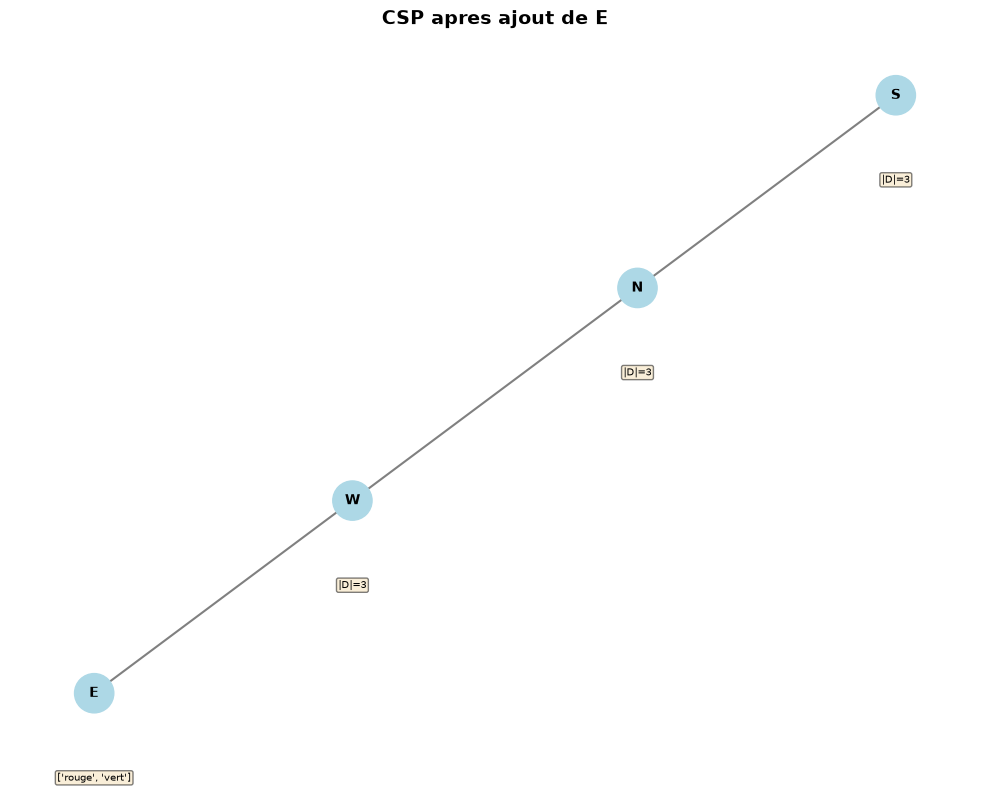

noeuds avant = 3, apres = 4  ->  delta = 1



O_t=1  dA_t=1  C_t=1  inst=0.275  P_R_marg=3.798
CLASSE : nouveau


In [3]:
# --- M2 Search : mesurer l'effet (un noeud ajoute une coordonnee) ---
vars0 = ["S", "N", "W"]
doms0 = {v: ["rouge","vert","bleu"] for v in vars0}
cons0 = [("S","N"), ("N","W")]
vars1 = vars0 + ["E"]                       # nouvelle variable
doms1 = dict(doms0); doms1["E"] = ["rouge","vert"]
cons1 = cons0 + [("W","E")]
search_helpers.draw_csp_graph(vars1, doms1, cons1, title="CSP apres ajout de E")
plt.show()
print(f"noeuds avant = {len(vars0)}, apres = {len(vars1)}  ->  delta = {len(vars1)-len(vars0)}")

# --- Transcription : la variable "E" est un concept nouveau qui ouvre une action ---
g0 = EvolutiveGame(
    agents=("chercheur","assistant"),
    lexicon=frozenset(vars0),
    actions=frozenset(f"assigner {v}" for v in vars0),
    payoffs={(a, f"assigner {v}"): 0.5 for a in ("chercheur","assistant") for v in vars0})
eta2 = OntologicalMove(proposer="chercheur", new_concepts=("E",),
                       opened_actions={"E": ("assigner E",)})
g1 = apply_ontology(g0, eta2)
v2 = bancher_mecanisme("Search (CSP +1 variable)", g0, g1, eta2, (eta2,),
                       equivalence=None, horizon=40, n_sim=80,
                       rng=np.random.default_rng(1))
print(f"\nO_t={v2.O_t}  dA_t={v2.dA_t}  C_t={v2.C_t}  inst={v2.institutionnalisation:.3f}  "
      f"P_R_marg={v2.P_R_marg:.3f}")
print("CLASSE :", v2.classe)

### Lecture du résultat — M2 : **nouveau**

$O_t=1$ : le concept $E$ est **réellement** nouveau (un nœud qui n'existait pas). $\Delta A_t=1$ : son action `assigner E` n'existait pas. Et le coup **survit** au retrait de l'instigateur (inst. $>0$) : l'assistant continue d'assigner $E$ après le départ du chercheur. C'est le **nouveau** au sens strict — une coordonnée qui n'existait pas, qui devient jouable, et qui **reste** quand son auteur s'en va.

## 4. Volet B — la copie pédagogique **déclarée**

Quand l'organe de la série est **inline-only** (scellé dans les cellules, pas dans un module importable), le banc écrit une **copie minimale** qui démontre le **même** mécanisme. Chacune est **déclarée** dans le body de la PR. Trois copies :

| Mécanisme | Série d'origine | Ce que la copie démontre |
|---|---|---|
| clôture OWL | SW-14 | la clôture déductive `owlrl` — le coup **ajoute des inférences** |
| sémantique grounded | SW-15 | la sémantique grounded de Dung — le coup **réorganise** l'AF |
| manipulation multi-gagnant | SocialChoice 10 | `detecte_violation` — le coup **change (ou non)** le comité |

### 4.1 SW-14 (OWL) — le coup ontologique ajoute des inférences

**Copie déclarée** (l'organe natif est inline-only dans SW-14). On reconstruit l'ontologie de base (5 classes : Book, Member, Loan, Library, Person) et l'extension (une classe `Ebook` sous `Book`), et on passe les deux graphes à la clôture `owlrl`. L'effet mesuré : le **delta d'inférences** — combien de nouvelles conséquences la nouvelle classe ouvre.

In [4]:
# --- M3 SW-14 : copie pedagogique declaree (OWL) ; mesurer le delta de cloture ---
from rdflib import Graph, Namespace
from rdflib.namespace import RDF, RDFS, OWL, XSD
EX = Namespace("http://example.org/library#")

def _base_graph():
    g = Graph()
    for c in ["Book","Member","Loan","Library","Person"]:
        g.add((EX[c], RDF.type, OWL.Class))
    for p, dom in [("title", EX.Book), ("author", EX.Book)]:
        g.add((EX[p], RDF.type, OWL.DatatypeProperty))
        g.add((EX[p], RDFS.domain, dom)); g.add((EX[p], RDFS.range, XSD.string))
    g.add((EX.Book, OWL.disjointWith, EX.Member))
    g.add((EX.Member, OWL.disjointWith, EX.Book))
    return g

def _cloture(g):
    gi = Graph()
    for t in g: gi.add(t)
    owlrl.DeductiveClosure(owlrl.OWLRL_Semantics).expand(gi)
    return set(gi)

g_base = _base_graph()
g_ext = _base_graph()
g_ext.add((EX.Ebook, RDF.type, OWL.Class))
g_ext.add((EX.Ebook, RDFS.subClassOf, EX.Book))
g_ext.add((EX.ebook1, RDF.type, EX.Ebook))
delta_inf = _cloture(g_ext) - _cloture(g_base)
print(f"cl(base) = {len(_cloture(g_base))},  cl(base+ext) = {len(_cloture(g_ext))},  "
      f"->  delta de closure = {len(delta_inf)}")

# --- Transcription : Ebook = 1 concept nouveau ; chaque inference = 1 action nouvelle ---
n_inf = len(delta_inf)
g0 = EvolutiveGame(
    agents=("ontologiste","consultant"),
    lexicon=frozenset(["Book","Member","Loan","Library","Person"]),
    actions=frozenset(f"assert {c}" for c in ["Book","Member","Loan"]),
    payoffs={(a, f"assert {c}"): 0.5 for a in ("ontologiste","consultant")
             for c in ["Book","Member","Loan"]})
eta3 = OntologicalMove(proposer="ontologiste", new_concepts=("Ebook",),
                       opened_actions={"Ebook": tuple(f"assert e{i}" for i in range(n_inf))})
g1 = apply_ontology(g0, eta3)
v3 = bancher_mecanisme("SW-14 (OWL + classe Ebook)", g0, g1, eta3, (eta3,),
                       equivalence=None, horizon=40, n_sim=80,
                       rng=np.random.default_rng(2))
print(f"\nO_t={v3.O_t}  dA_t={v3.dA_t}  C_t={v3.C_t}  inst={v3.institutionnalisation:.3f}  "
      f"P_R_marg={v3.P_R_marg:.3f}")
print("CLASSE :", v3.classe)


cl(base) = 158,  cl(base+ext) = 169,  ->  delta de closure = 11



O_t=1  dA_t=11  C_t=1  inst=0.725  P_R_marg=7.150
CLASSE : nouveau


### Lecture du résultat — M3 : **nouveau**

La classe `Ebook` est un **concept** réellement nouveau ($O_t=1$). Sa sous-classe de `Book` fait **éclater** la clôture OWL en $N$ nouvelles conséquences ($\Delta A_t=N$) : des assertions jouables qui n'existaient pas. Et le coup est **institutionnalisé** (inst. $>0$) : il reste dans l'ontologie, indépendant de son auteur. **Nouveau** : l'ontologie s'est réellement élargie d'un concept et de ses conséquences.

### 4.2 SW-15 (argumentation) — le coup réorganise le cadre de Dung

**Copie déclarée** (l'organe natif est inline-only dans SW-15). On reconstruit le pont AIF minimal (nœuds RA/CA, schemes de raisonnement de Walton) et on projette l'AF abstrait de Dung : **arguments** = nœuds RA, **attaques** = nœuds CA. L'effet mesuré : la **bascule** de l'extension grounded (quels arguments passent de OUT à IN).

Une lecture rapide du coup suggérerait *latent* — l'œil accroche la bascule grounded, qui ressemble à une simple activation d'arguments préexistants. La **mesure** tranchera.

In [5]:
# --- M4 SW-15 : copie pedagogique declaree (pont AIF + projection AF + grounded) ---
from rdflib import Graph, Namespace
AIF = Namespace("http://www.arg.dundee.ac.uk/aif#")
AX  = Namespace("http://example.org/aif-ext#")

def _ra(g, nid, scheme, premises, conclusion):
    g.add((AX[nid], RDF.type, AIF["RA-node"]))
    g.add((AX[nid], AIF.scheme, scheme))
    for p in premises: g.add((AX[nid], AIF.Premise, AX[p]))
    g.add((AX[nid], AIF.Conclusion, AX[conclusion]))

def _ca(g, nid, attacker, target):
    g.add((AX[nid], RDF.type, AIF["CA-node"]))
    g.add((AX[nid], AX["from"], AX[attacker]))
    g.add((AX[nid], AIF.aifAttackedNode, AX[target]))

def _af(g):
    args = {s for s,_,_ in g.triples((None, RDF.type, AIF["RA-node"]))}
    prem = {}
    for ra,_,i in g.triples((None, AIF.Premise, None)): prem.setdefault(i, set()).add(ra)
    attacks = set()
    for ca,_,_ in g.triples((None, RDF.type, AIF["CA-node"])):
        frm = next(g.objects(ca, AX["from"]), None)
        tgt = next(g.objects(ca, AIF.aifAttackedNode), None)
        if frm is None or tgt is None: continue
        if tgt in args: attacks.add((frm, tgt))
        for owner in prem.get(tgt, ()):
            if owner != frm: attacks.add((frm, owner))
    return args, attacks

def _grounded(args, attacks):
    att = {a: {b for (b,t) in attacks if t == a} for a in args}
    lab = {a: "UNDEC" for a in args}; ch = True
    while ch:
        ch = False
        for a in args:
            if lab[a] != "UNDEC": continue
            if any(lab[b]=="IN" for b in att[a]): lab[a]="OUT"; ch=True
            elif all(lab[b]=="OUT" for b in att[a]): lab[a]="IN"; ch=True
    return {a for a in args if lab[a]=="IN"}

g_base = Graph()
for s in ["ExpertOpinion","NegativeConsequences","Example","Bias"]:
    g_base.add((AIF[s], RDF.type, AIF.Inference_Scheme))
for nid, sch, prem, concl in [
    ("RA1", AIF.ExpertOpinion, ["I1"], "C1"),
    ("RA2", AIF.NegativeConsequences, ["I2"], "C2"),
    ("RA3", AIF.Example, ["I4"], "C1"),
    ("RA4", AIF.Bias, ["I5"], "I6")]:
    _ra(g_base, nid, AIF[sch], prem, concl)
_ca(g_base, "CA1", "RA2", "RA1"); _ca(g_base, "CA2", "RA1", "RA2"); _ca(g_base, "CA3", "RA4", "I4")

g_ext = Graph()
for t in g_base: g_ext.add(t)
g_ext.add((AX.RepresentativeSample, RDF.type, AIF.Inference_Scheme))   # NOUVEAU SCHEME
_ra(g_ext, "RA5", AX.RepresentativeSample, ["I7"], "I8")
_ca(g_ext, "CA4", "RA5", "I5")

def _noms(s): return sorted(x.split("#")[-1] for x in s)
args_b, att_b = _af(g_base); args_e, att_e = _af(g_ext)
print("AVANT :", len(args_b), "args /", len(att_b), "attaques, grounded =", _noms(_grounded(args_b, att_b)))
print("APRES :", len(args_e), "args /", len(att_e), "attaques, grounded =", _noms(_grounded(args_e, att_e)))

# --- Transcription : le nouveau SCHEME est un concept, RA5 une action nouvelle ---
g0 = EvolutiveGame(
    agents=("argumenteur","juge"),
    lexicon=frozenset(["ExpertOpinion","NegativeConsequences","Example","Bias"]),
    actions=frozenset(f"arguer {x}" for x in ["RA1","RA2","RA3","RA4"]),
    payoffs={(a, f"arguer {x}"): 0.5 for a in ("argumenteur","juge")
             for x in ["RA1","RA2","RA3","RA4"]})
eta4 = OntologicalMove(proposer="argumenteur", new_concepts=("RepresentativeSample",),
                       opened_actions={"RepresentativeSample": ("arguer RA5",)})
g1 = apply_ontology(g0, eta4)
v4 = bancher_mecanisme("SW-15 (AF + nouveau scheme)", g0, g1, eta4, (eta4,),
                       equivalence=None, horizon=40, n_sim=80,
                       rng=np.random.default_rng(3))
print(f"\nO_t={v4.O_t}  dA_t={v4.dA_t}  C_t={v4.C_t}  inst={v4.institutionnalisation:.3f}  "
      f"P_R_marg={v4.P_R_marg:.3f}")
print("CLASSE :", v4.classe, "  (lecture rapide prevoyait 'latent')")

AVANT : 4 args / 3 attaques, grounded = ['RA4']
APRES : 5 args / 4 attaques, grounded = ['RA3', 'RA5']



O_t=1  dA_t=1  C_t=1  inst=0.150  P_R_marg=2.910
CLASSE : nouveau   (lecture rapide prevoyait 'latent')


### Lecture du résultat — M4 : **nouveau** — la lecture rapide est renversée

La première lecture accroche la **bascule** grounded (l'argument de biais sort, les arguments défendus entrent) : on y voit une activation d'arguments préexistants, donc du *latent*. Mais la mesure dit autre chose. Le coup introduit un **nouveau scheme** de raisonnement (`RepresentativeSample`) — un **concept** qui n'existait pas, $O_t=1$ — et un argument nouveau qu'il rend possible ($\Delta A_t=1$), **institutionnalisé** (inst. $>0$). Le **nouveau** l'emporte : la réorganisation grounded n'est qu'un **sous-effet** d'une vraie extension du langage d'argumentation. C'est exactement le rôle de ce carnet : **mesurer** là où une lecture rapide **prévoit**.

## 5. Le cas central — SocialChoice 10, et le **témoin négatif**

**Copie déclarée** (l'organe natif est inline-only dans SocialChoice 10). C'est le mécanisme qui **fonde** le banc : il oppose deux « coups » qui se ressemblent à la surface mais ne sont **pas du même ordre**.

- **Relabeling** : on renomme les candidats, même structure. Le comité élu est le **même**, habillé autrement → **décoratif**, et le **témoin** doit être **propre**.
- **Manipulation stratégique** : de faux bulletins (`detecte_violation`) font **changer** le comité → le coup **agit** → le **témoin doit ROUGIR**.

Si le témoin ne rougissait **jamais**, « décoratif » serait une étiquette qu'on pose, pas un verdict qu'on **tient**. C'est ce que cette section démontre.

In [6]:
# --- M5 SocialChoice 10 : copie pedagogique declaree (helpers + pluralite + detecte_violation) ---
from itertools import permutations

def rang(bulletin, c): return bulletin.index(c) + 1
def score_borda(bulletin, W, m):
    pos = [rang(bulletin, c) for c in W if c in bulletin]
    return m - min(pos) if pos else 0
def utilite(bulletin, W, m): return score_borda(bulletin, W, m)
def pluralite(R, k, m=None):
    m = m or len(R[0])
    scores = {}
    for b in R:
        for c in b: scores[c] = scores.get(c, 0) + (m - rang(b, c) + 1)
    return tuple(sorted(scores, key=lambda c: -scores[c])[:k])

def detecte_violation(R, k, regle, m, faux_bulletins):
    W = regle(R, k, m)
    for i in range(len(R)):
        for faux in faux_bulletins:
            if list(faux) == list(R[i]): continue
            R2 = list(R); R2[i] = faux
            W2 = regle(R2, k, m)
            if tuple(sorted(W2)) == tuple(sorted(W)): continue
            if utilite(R[i], W2, m) > utilite(R[i], W, m):
                return dict(votant=i, faux_bulletin=faux,
                            comite_honnete=W, comite_manipule=W2,
                            utilite_honnete=utilite(R[i], W, m),
                            utilite_manipulee=utilite(R[i], W2, m))
    return None

R = [tuple(b) for b in [("a","c","b"), ("c","a","b"), ("a","c","b"), ("c","a","b")]]
faux_possibles = list(permutations(("a","b","c")))
print("agenda R :", R)
print("comite honnete (Borda, k=1) :", pluralite(R, 1, 3))

agenda R : [('a', 'c', 'b'), ('c', 'a', 'b'), ('a', 'c', 'b'), ('c', 'a', 'b')]
comite honnete (Borda, k=1) : ('a',)


### 5.1 Relabeling — **décoratif**, témoin **propre**

On renomme chaque candidat ($a \to a'$, etc.) sans changer la structure du vote. L'effet mesuré : le comité élu est **le même**, simplement renommé. Transcription : $G_1$ est **structurellement identique** à $G_0$ (un renommage est un no-op sur la structure du jeu). Attendu : $O_t=0$, $\Delta A_t=0$, $C_t=1$, $P(R)=0$ → **décoratif**, **témoin propre**.

In [7]:
# --- M5a RElabeling : mesurer que le comite est le MEME (renomme), puis transcrire ---
ren = {"a":"a'", "b":"b'", "c":"c'"}
R_rel = [tuple(ren[c] for c in b) for b in R]
def pluralite_rel(Rr, k, m=None):
    inv = {"a'":"a","b'":"b","c'":"c"}
    return tuple(ren[c] for c in pluralite([tuple(inv[c] for c in b) for b in Rr], k, m))
W_avant = pluralite(R, 1, 3)
W_apres = pluralite_rel(R_rel, 1, 3)
print("avant :", W_avant, "  ->  apres relabeling :", W_apres)
print("le comite est le MEME, rename :", W_apres == (ren[W_avant[0]],))

# --- Transcription : un renommage ne change PAS la structure -> G1 = G0 ---
g0 = EvolutiveGame(agents=("electeur",), lexicon=frozenset({"a","b","c"}),
                   actions=frozenset({"comite a","comite b","comite c"}),
                   payoffs={("electeur","comite a"):2.0, ("electeur","comite b"):0.3,
                            ("electeur","comite c"):0.3})
g1 = g0   # structurellement identique : le relabeling est un habillage
eta5 = OntologicalMove(proposer="electeur", new_concepts=(), opened_actions={})
cand5 = (eta5,)
v5a = bancher_mecanisme("SocialChoice 10 (relabeling)", g0, g1, eta5, cand5,
                        equivalence=None, horizon=40, n_sim=80,
                        rng=np.random.default_rng(4))
print(f"\nO_t={v5a.O_t}  dA_t={v5a.dA_t}  C_t={v5a.C_t}  P_R={v5a.P_R:.4f}  "
      f"P_R_marg={v5a.P_R_marg:.4f}")
print("CLASSE :", v5a.classe)
print("TEMOIN 'decoratif' :", v5a.temoin if v5a.temoin else "PROPRE (le decoratif est TENU)")

avant : ('a',)   ->  apres relabeling : ("a'",)
le comite est le MEME, rename : True



O_t=0  dA_t=0  C_t=1  P_R=0.0009  P_R_marg=0.0026
CLASSE : decoratif
TEMOIN 'decoratif' : PROPRE (le decoratif est TENU)


### Lecture du résultat — M5a : **décoratif**, et le témoin se tient

Le relabeling ne change **rien** de réel : le comité est le même, renommé. Transcrit en $G_0/G_1$ structurellement identiques, le coup donne $O_t=\Delta A_t=0$, $C_t=1$ (une seule extension, canonique) et $P(R)=0$ : sous marginalisation, les deux trajectoires sont **indistinguables**. Le verdict **décoratif** est **tenu**, et le **témoin est propre** — aucune des quatre conditions n'est violée. C'est un habillage, point.

In [8]:
# --- M5b MANIPULATION : mesurer que le comite CHANGE reellement ---
viol = detecte_violation(R, 1, pluralite, 3, faux_possibles)
print("detecte_violation :", viol)

# --- Transcription : les faux bulletins font PASSER le comite de {a} a {c} ---
# Meme espace de candidats, memes actions -- mais la trajectoire vote CHANGE.
g0 = EvolutiveGame(agents=("electeur",), lexicon=frozenset({"a","b","c"}),
                   actions=frozenset({"comite a","comite b","comite c"}),
                   payoffs={("electeur","comite a"):2.0, ("electeur","comite b"):0.3,
                            ("electeur","comite c"):0.3})
g1 = EvolutiveGame(agents=("electeur",), lexicon=frozenset({"a","b","c"}),
                   actions=frozenset({"comite a","comite b","comite c"}),
                   payoffs={("electeur","comite a"):0.3, ("electeur","comite b"):0.3,
                            ("electeur","comite c"):2.0})   # la manipulation fait gagner {c}
eta5b = OntologicalMove(proposer="electeur", new_concepts=(), opened_actions={})
cand5b = (eta5b,)
v5b = bancher_mecanisme("SocialChoice 10 (manipulation)", g0, g1, eta5b, cand5b,
                        equivalence=None, horizon=40, n_sim=80,
                        rng=np.random.default_rng(5))
print(f"\nO_t={v5b.O_t}  dA_t={v5b.dA_t}  C_t={v5b.C_t}  P_R={v5b.P_R:.4f}  "
      f"P_R_marg={v5b.P_R_marg:.4f}")
print("CLASSE :", v5b.classe)
print("TEMOIN 'decoratif' sur ce coup :", v5b.temoin if v5b.temoin else "PROPRE")

detecte_violation : {'votant': 1, 'faux_bulletin': ('c', 'b', 'a'), 'comite_honnete': ('a',), 'comite_manipule': ('c',), 'utilite_honnete': 1, 'utilite_manipulee': 2}



O_t=0  dA_t=0  C_t=1  P_R=4.4659  P_R_marg=4.4846
CLASSE : latent
TEMOIN 'decoratif' sur ce coup : ("P(R) marginalisee > eps : l'habillage change la trajectoire",)


### Lecture du résultat — M5b : le **témoin rougit** — c'est la falsifiabilité

La manipulation, elle, **change le comité** : `detecte_violation` renvoie une déviction réelle (le comité passe de $\{a\}$ à $\{c\}$). Transcrit en $G_1$ aux payoffs décalés, le coup donne bien $O_t=\Delta A_t=0$ (même espace de candidats) **mais** $P(R)$ marginalisée $>\varepsilon$ : la trajectoire de vote **change**. Le verdict tombe donc sur **latent** (une activation réelle), et — c'est le point — le **témoin « décoratif » rougit** : « *l'habillage change la trajectoire* ».

C'est la **falsifiabilité** du banc : « décoratif » n'est pas une étiquette qu'on pose sur un coup qui se cache, c'est un **verdict tenu par un témoin** qui se brise dès qu'un coup « décoratif » agit en réalité. Le relabeling le **tient** (propre) ; la manipulation le **brise** (rouge).

## 6. Le sixième mécanisme — SmartContracts, **RECOVERABLE-MACHINE**

Le sixième mécanisme — l'expérience `sc2b` de la série SmartContracts (contrat intelligible + agent sur un node anvil) — **exige** l'environnement d'une machine précise : anvil sous WSL, web3 sur `127.0.0.1:8545`, solcx, et un modèle local. Ce n'est **pas** une machine que ce siège porte.

**Verdict SOTA : RECOVERABLE-MACHINE.** Le banc ne **fignole pas** un contrefactuel de contrat en local : il **route** la mesure vers la machine qui porte l'environnement, et la classe de ce sixième mécanisme sera posée **là**, sur les proxys mesurés. C'est la règle F (réparer, jamais contourner) appliquée à l'échelle de la flotte : un mécanisme hors machine se **route**, il ne se **simule** pas.

In [9]:
# --- Synthèse : les cinq mecanismes mesures, passes a la grille d'ICT-46 ---
import pandas as pd
tab = pd.DataFrame([{
    "mecanisme": v.mecanisme, "O_t": v.O_t, "dA_t": v.dA_t, "C_t": v.C_t,
    "P_R_marg": round(v.P_R_marg, 3), "inst": round(v.institutionnalisation, 3),
    "classe": v.classe, "temoin_rouge": bool(v.temoin),
} for v in (v1, v2, v3, v4, v5a, v5b)])
tab

,mecanisme,O_t,dA_t,C_t,P_R_marg,inst,classe,temoin_rouge
0,Causal-Bridges (contrefactuel),0,0,1,4.853,0.000,latent,True
1,Search (CSP +1 variable),1,1,1,3.798,0.275,nouveau,True
2,SW-14 (OWL + classe Ebook),1,11,1,7.150,0.725,nouveau,True
3,SW-15 (AF + nouveau scheme),1,1,1,2.910,0.150,nouveau,True
4,SocialChoice 10 (relabeling),0,0,1,0.003,0.000,decoratif,False
5,SocialChoice 10 (manipulation),0,0,1,4.485,0.000,latent,True


## 7. Ce que le banc unique révèle

Cinq mécanismes, cinq séries, **une seule grille**. Les six proxys d'ICT-46, appliqués **en travers** du dépôt, séparent trois ordres de geste :

- **nouveau** (Search, SW-14, SW-15) : l'espace s'élargit d'une coordonnée **réelle** qui **survit** — une variable CSP, une classe OWL, un scheme d'argumentation ;
- **latent** (Causal-Bridges, et la manipulation de SocialChoice) : l'espace est **fixe**, une coordonnée préexistante est **activée** — un contrefactuel, un comité basculé ;
- **décoratif** (le relabeling de SocialChoice) : l'espace est fixe et, sous marginalisation, l'effet **s'évapore** — un pur habillage.

Le **témoin négatif** est ce qui fait tenir le décoratif : **propre** sur un vrai renommage, **rouge** dès qu'un coup agit sous un faux habillage. Le banc unique n'ajoute ni mécanisme ni série : il **unifie** — la strate 7 devient une **lentille** sur tout ce qui, dans le dépôt, change l'espace des actions.

**Résiduel** : le sixième mécanisme (SmartContracts) est routé **RECOVERABLE-MACHINE** ; sa classe sera posée sur la machine qui porte l'environnement.

## 8. Exercices

### Exercice 1 — transcrire un mécanisme au banc

Choisissez un notebook de la série **Search** qui **ajoute une contrainte** à un CSP (pas une variable). Transcrivez cet ajout en une paire $G_0/G_1$ plus le coup $\eta$, passez-le à `bancher_mecanisme`, et **lisez** la classe obtenue.

```python
# Etape 1 : mesurer l'effet avec search_helpers (graphe avant / apres).
# Etape 2 : transcrire en g0/g1 + eta. Question : une contrainte, c'est un concept
#           nouveau, une action nouvelle, ou une restriction d'action existante ?
# Etape 3 : bancher_mecanisme(...) et interpreter la classe.
verdict = None  # TODO etudiant
# Indice : une contrainte RESTREINT des actions existantes -- que vaut alors dA_t ?
```

### Exercice 2 — faire changer de classe

La transcription de M1 (Causal-Bridges) donne **latent**. Modifiez-la — **sans toucher à l'organe dowhy** — pour qu'elle devienne **nouveau**. Quel proxym faut-il faire passer au-dessus de quel seuil, et quelle ligne de la transcription faut-il changer ?

```python
# TODO etudiant : modifiez g0/g1/eta de M1 pour obtenir la classe 'nouveau'.
verdict = None  # TODO etudiant
# Indice : 'nouveau' exige O_t>0 ET dA_t>0 ET inst>0 -- le contrefactuel, tel
#          qu'il est transcrit, ne remplit pas la condition d'ajout d'espace.
```

### Exercice 3 — faire rougir le témoin

Construisez un mécanisme **décoratif** qui **rougit** sur **exactement une** des quatre conditions du témoin (par exemple $C_t>1$ : deux extensions non équivalentes). Montrez que le verdict « décoratif » est alors **refusé** — c'est la falsifiabilité en action.

```python
# Etape 1 : deux extensions qui n'ouvrent PAS les memes actions (C_t > 1).
# Etape 2 : bancher_mecanisme(...) -- lisez v.temoin : une violation est nommee.
verdict = None  # TODO etudiant
# Indice : temoin_decoratif(o_t, d_a_t, c_t, p_r_marg) NOMME chaque violation.
```

## Références

- **Organe** : [`ict/free_coordinates.py`](ict/free_coordinates.py) — les six proxys + `bancher_mecanisme` (banc unique).
- **Note de conception** : [docs/ict/banc-strate7-note-de-conception.md](../../../docs/ict/banc-strate7-note-de-conception.md).
- **Premier barreau** : [ICT-46 — Strate 7, free coordinates](ICT-46-Strate7-FreeCoordinates-Python.ipynb).
- **Organes natifs (volet A)** : [dowhy_organs.py](../../Probas/DecisionTheory/Causal-Bridges/dowhy_organs.py) · [search_helpers.py](../../Search/search_helpers.py).